# Student Survey: Standardization and Exploratory Analysis

This notebook performs a second standardization pass on the cleaned
student survey and produces descriptive tables and figures.

It preserves original answers, flags school-cluster inconsistencies,
standardizes technology selections, and separates substantive written
answers from blank or punctuation-only responses.

Unresolved duplicate candidates remain in the descriptive dataset.
Results are provisional until duplicate decisions are completed.

In [1]:
%pip install pandas openpyxl matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


## 1. Load Data and Prepare Output Folders

Load the Cleaned Data sheet while preserving explicit text answers
such as "None" and "NA".

Create dedicated folders for student tables and figures.

In [2]:
from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display


current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data" / "cleaned").is_dir()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot locate data/cleaned.")

CLEANED = ROOT / "data" / "cleaned"
TABLES = ROOT / "outputs" / "tables" / "students"
FIGURES = ROOT / "outputs" / "figures" / "students"

for folder in [TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(
    CLEANED / "students_pre_event_cleaned.xlsx",
    sheet_name="Cleaned Data",
    keep_default_na=False,
    na_values=[""],
)

assert df["response_id"].notna().all()
assert df["response_id"].is_unique

PURPLE = "#6F42A6"
ORANGE = "#E8913A"
RATING_COLORS = ["#D9D9D9", "#B8ABD3", "#9474B6", "#70449A", "#442260"]

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

tables = {}

print("Loaded submissions:", len(df))
print("Columns:", df.shape[1])

Loaded submissions: 241
Columns: 51


## 2. Standardize Categories and Validate Ratings

Normalize spacing in categorical fields without rewriting original
open-ended responses.

Convert grade level to a numeric value and validate rating responses.
Invalid values are recorded and replaced with missing values only in
the standardized dataset.

School clusters remain categorical identifiers.

In [3]:
def normalize_text(value):
    if pd.isna(value):
        return pd.NA

    text = unicodedata.normalize("NFKC", str(value))
    text = re.sub(r"\s+", " ", text).strip()

    return text if text else pd.NA


def parse_bool(series):
    values = series.astype("string").str.strip().str.casefold()

    mapping = {
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "1.0": True,
        "0.0": False,
    }

    unknown = values.notna() & ~values.isin(mapping)

    if unknown.any():
        raise ValueError(
            f"Unexpected Boolean values: {values[unknown].unique()}"
        )

    return values.map(mapping).astype("boolean")


category_columns = [
    "school_name",
    "grade_level",
    "gender",
    "prior_devcon",
    "project_experience",
    "heard_of_ct",
    "climate_familiarity",
]

for column in category_columns:
    df[column] = df[column].map(normalize_text)

for column in ["prior_devcon", "project_experience"]:
    original = df[column].astype("string")
    standardized = original.str.casefold().map({
        "yes": "Yes",
        "no": "No",
    })

    unexpected = original.notna() & standardized.isna()

    if unexpected.any():
        raise ValueError(
            f"Unexpected values in {column}: "
            f"{original[unexpected].unique()}"
        )

    df[column] = standardized

df["grade_numeric"] = pd.to_numeric(
    df["grade_level"].astype("string").str.extract(
        r"^Grade\s+(\d+)$",
        expand=False,
    ),
    errors="coerce",
).astype("Int64")

invalid_grades = ~df["grade_numeric"].isin([5, 6, 7, 8, 9])

if invalid_grades.any():
    display(df.loc[invalid_grades, ["response_id", "grade_level"]])
    raise ValueError("Review unexpected or missing grade levels.")

rating_columns = [
    "tech_confidence",
    "environment_belief",
    "tech_interest",
    "community_tech_interest",
    "stem_interest",
    "ct_familiarity_score",
    "ct_decomposition",
    "ct_patterns",
    "ct_steps",
    "ct_iteration",
    "ct_application",
    "community_ideas",
    "environmental_teamwork",
    "youth_impact",
    "tech_creation_confidence",
    "tech_creator_identity",
]

rating_issues = []

for column in rating_columns:
    original = df[column].copy()
    numeric = pd.to_numeric(original, errors="coerce")

    invalid = original.notna() & ~numeric.isin([1, 2, 3, 4, 5])

    for index in df.index[invalid]:
        rating_issues.append({
            "response_id": df.loc[index, "response_id"],
            "column": column,
            "original_value": original.loc[index],
            "action": "Set standardized value to missing",
        })

    df[column] = numeric.where(
        numeric.isin([1, 2, 3, 4, 5])
    ).astype("Int64")

tables["rating_validation"] = pd.DataFrame(
    rating_issues,
    columns=["response_id", "column", "original_value", "action"],
)

print("Invalid rating values:", len(rating_issues))

Invalid rating values: 0


## 3. Review Duplicate Candidates and School Clusters

Create normalized name keys for review, preserving original names.

Apply only explicitly verified duplicate decisions. Excluded submissions
remain documented in an exclusion table.

Check whether the same school has multiple reported cluster values.
Do not automatically choose a cluster when respondents disagree.

In [4]:
# Enter IDs only after reviewing the duplicate submissions.
CONFIRMED_EXCLUDE_IDS = set()

# Example structure — leave empty until decisions are verified:
# CONFIRMED_EXCLUDE_IDS = {"S0005"}

unknown_ids = CONFIRMED_EXCLUDE_IDS - set(df["response_id"])

if unknown_ids:
    raise ValueError(f"Unknown response IDs: {unknown_ids}")

tables["excluded_submissions"] = df.loc[
    df["response_id"].isin(CONFIRMED_EXCLUDE_IDS),
    ["response_id", "source_excel_row"],
].copy()

df = df.loc[
    ~df["response_id"].isin(CONFIRMED_EXCLUDE_IDS)
].copy()

df["name_key"] = (
    df["first_name"].map(normalize_text).astype("string").str.casefold()
    + "|"
    + df["last_name"].map(normalize_text).astype("string").str.casefold()
)

df["school_key"] = (
    df["school_name"].astype("string").str.casefold()
)

df["possible_duplicate"] = (
    df["name_key"].notna()
    & df["name_key"].duplicated(keep=False)
)

tables["duplicate_candidates"] = df.loc[
    df["possible_duplicate"],
    [
        "response_id",
        "timestamp",
        "first_name",
        "last_name",
        "school_name",
        "grade_level",
    ],
].sort_values(["last_name", "first_name", "timestamp"])

cluster_pairs = (
    df[["school_key", "school_name", "school_cluster"]]
    .dropna()
    .drop_duplicates()
)

cluster_counts = cluster_pairs.groupby(
    "school_key"
)["school_cluster"].nunique()

conflicting_school_keys = set(
    cluster_counts[cluster_counts > 1].index
)

df["school_cluster_inconsistent"] = df["school_key"].isin(
    conflicting_school_keys
)

tables["school_cluster_review"] = cluster_pairs.loc[
    cluster_pairs["school_key"].isin(conflicting_school_keys)
].sort_values(["school_name", "school_cluster"])

display(tables["school_cluster_review"])

print("Duplicate-candidate rows:", int(df["possible_duplicate"].sum()))
print("Schools with multiple clusters:", len(conflicting_school_keys))

,school_key,school_name,school_cluster
25,bambang elementary school,Bambang Elementary School,3
58,bambang elementary school,Bambang Elementary School,6
106,buting elementary school,Buting Elementary School,4
54,buting elementary school,Buting Elementary School,6
50,dela paz elementary school,Dela Paz Elementary School,4
3,dela paz elementary school,Dela Paz Elementary School,10
38,dr. sixto antonio elementary school,Dr. Sixto Antonio Elementary School,3
223,dr. sixto antonio elementary school,Dr. Sixto Antonio Elementary School,7
96,f. legaspi memorial school,F. Legaspi Memorial School,2
97,f. legaspi memorial school,F. Legaspi Memorial School,3


Duplicate-candidate rows: 20
Schools with multiple clusters: 19


## 4. Standardize Technology Selections

Standardize spelling and capitalization of technology labels.

Retain technologies beyond the six original indicators. Contradictory
answers containing "None of the above" and another selection are
excluded from technology-frequency calculations only.

Create updated binary indicators. Missing and contradictory responses
remain missing rather than becoming zero.

In [5]:
TECHNOLOGY_ALIASES = {
    "artificial intelligence (ai)": "Artificial Intelligence (AI)",
    "scratch": "Scratch",
    "python": "Python",
    "micro:bit": "Micro:bit",
    "arduino": "Arduino",
    "climate action kit": "Climate Action Kit",
    "c++": "C++",
    "vexcode.vr": "VEXcode VR",
    "vexcode vr": "VEXcode VR",
    "wokwi": "Wokwi",
    "mbot": "mBot",
    "pc hardware & computer troubleshooting": (
        "PC hardware and troubleshooting"
    ),
    "none of the above": "None of the above",
}


def technology_list(value):
    if pd.isna(value):
        return []

    tokens = []

    for item in str(value).split(";"):
        item = normalize_text(item)

        if pd.isna(item):
            continue

        tokens.append(
            TECHNOLOGY_ALIASES.get(item.casefold(), item)
        )

    return list(dict.fromkeys(tokens))


tech_lists = df["technologies_cleaned"].map(technology_list)

df["technologies_standardized"] = tech_lists.map(
    lambda values: "; ".join(values) if values else pd.NA
)

df["technology_conflict"] = tech_lists.map(
    lambda values: (
        "None of the above" in values and len(values) > 1
    )
)

technology_valid = (
    tech_lists.map(len).gt(0)
    & ~df["technology_conflict"]
)

TECH_INDICATORS = {
    "Artificial Intelligence (AI)": "selected_ai",
    "Scratch": "selected_scratch",
    "Python": "selected_python",
    "Micro:bit": "selected_microbit",
    "Arduino": "selected_arduino",
    "Climate Action Kit": "selected_climate_kit",
    "C++": "selected_cpp",
    "VEXcode VR": "selected_vexcode",
    "Wokwi": "selected_wokwi",
    "mBot": "selected_mbot",
    "PC hardware and troubleshooting": "selected_pc_hardware",
}

for label, column in TECH_INDICATORS.items():
    df[column] = pd.array(
        [
            int(label in tech_lists.loc[index])
            if technology_valid.loc[index]
            else pd.NA
            for index in df.index
        ],
        dtype="Int64",
    )

print("Valid technology responses:", int(technology_valid.sum()))
print("Contradictory responses:", int(df["technology_conflict"].sum()))

Valid technology responses: 238
Contradictory responses: 3


## 5. Prepare Written Responses for Manual Theme Coding

Preserve original written answers.

Create normalized analysis text and classify responses as substantive,
punctuation-only, or missing.

Export a coding template for manual review. Theme labels should be
assigned after reading each response, not inferred solely from keywords.

Do not interpret written-response themes as objective knowledge scores.

In [6]:
text_columns = [
    "climate_problem",
    "learning_goals",
    "ct_definition",
]

coding_rows = []

for column in text_columns:
    normalized = df[column].map(normalize_text)

    substantive = normalized.map(
        lambda value: (
            False
            if pd.isna(value)
            else any(character.isalnum() for character in value)
        )
    )

    df[f"{column}_status"] = np.select(
        [
            normalized.isna(),
            normalized.notna() & ~substantive,
        ],
        ["Missing", "Punctuation only"],
        default="Substantive",
    )

    df[f"{column}_analysis"] = normalized.where(substantive, pd.NA)

    for index in df.index[substantive]:
        coding_rows.append({
            "response_id": df.loc[index, "response_id"],
            "question": column,
            "response_text": normalized.loc[index],
            "themes": "",
            "reviewed": False,
        })

coding_template = pd.DataFrame(coding_rows)
coding_path = TABLES / "students_theme_coding.csv"

# Protect any theme coding you have already entered.
if not coding_path.exists():
    coding_template.to_csv(
        coding_path,
        index=False,
        encoding="utf-8-sig",
    )
    print("Created:", coding_path.name)
else:
    print("Existing theme-coding file preserved.")

tables["written_response_quality"] = pd.concat(
    [
        df[f"{column}_status"]
        .value_counts()
        .rename_axis("status")
        .reset_index(name="count")
        .assign(question=column)
        for column in text_columns
    ],
    ignore_index=True,
)

display(tables["written_response_quality"])

Created: students_theme_coding.csv


,status,count,question
0,Substantive,241,climate_problem
1,Substantive,241,learning_goals
2,Substantive,240,ct_definition
3,Punctuation only,1,ct_definition


## 6. Create Reusable Table and Figure Functions

Calculate percentages using nonmissing answers.

Every frequency table records the valid denominator and missing count.
Figures are saved as 300-DPI PNG files.

In [7]:
PROVISIONAL = bool(df["possible_duplicate"].any())


def save_figure(fig, filename, note=""):
    status = (
        "Provisional submission-level results; duplicate review pending."
        if PROVISIONAL
        else "Submission-level results after recorded exclusions."
    )

    fig.text(
        0.01,
        0.01,
        status + (" " + note if note else ""),
        fontsize=8,
        color="#555555",
    )

    fig.tight_layout(rect=[0, 0.08, 1, 1])
    fig.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


def frequency_table(series, order=None):
    valid = series.dropna()
    counts = valid.value_counts()

    if order is not None:
        # Preserve unexpected categories rather than silently dropping them.
        extra = [value for value in counts.index if value not in order]
        counts = counts.reindex(list(order) + extra, fill_value=0)

    result = counts.rename_axis("category").reset_index(name="count")
    result["percent"] = (
        result["count"] / len(valid) * 100
        if len(valid)
        else np.nan
    )
    result["valid_n"] = len(valid)
    result["missing_n"] = int(series.isna().sum())

    return result


def bar_figure(table, title, filename, color=PURPLE):
    fig, ax = plt.subplots(
        figsize=(9, max(4, len(table) * 0.45))
    )

    positions = np.arange(len(table))

    bars = ax.barh(
        positions,
        table["percent"],
        color=color,
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(table["category"].astype(str))
    ax.invert_yaxis()
    ax.set_xlabel("Percentage of valid responses")
    ax.set_ylabel("")
    ax.set_title(title)

    ax.set_xlim(
        0,
        max(15, float(table["percent"].max()) * 1.25)
    )

    ax.bar_label(
        bars,
        labels=[
            f"{percent:.1f}% (n={count})"
            for percent, count in zip(
                table["percent"], table["count"]
            )
        ],
        padding=4,
        fontsize=9,
    )

    save_figure(fig, filename)

## 7. Describe Student Profiles, Experience, and Familiarity

Summarize grade, age, gender, school, prior experience, climate
familiarity, computational-thinking familiarity, and STEM interest.

Retain the full 1–5 STEM-interest distribution before any later
classification target is created.

,category,count,percent,valid_n,missing_n
0,Grade 5,21,8.713693,241,0
1,Grade 6,108,44.813278,241,0
2,Grade 7,32,13.278008,241,0
3,Grade 8,49,20.331950,241,0
4,Grade 9,31,12.863071,241,0


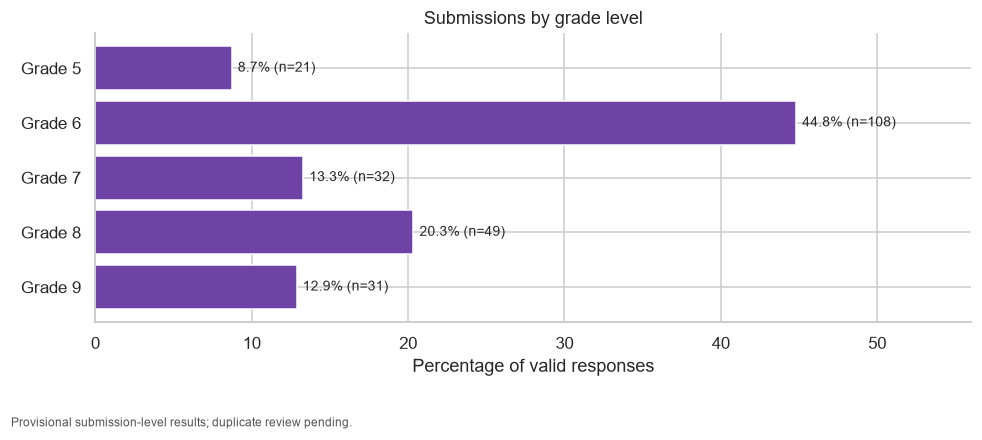

,category,count,percent,valid_n,missing_n
0,10,19,7.883817,241,0
1,11,97,40.248963,241,0
2,12,41,17.012448,241,0
3,13,47,19.502075,241,0
4,14,27,11.203320,241,0
5,15,10,4.149378,241,0


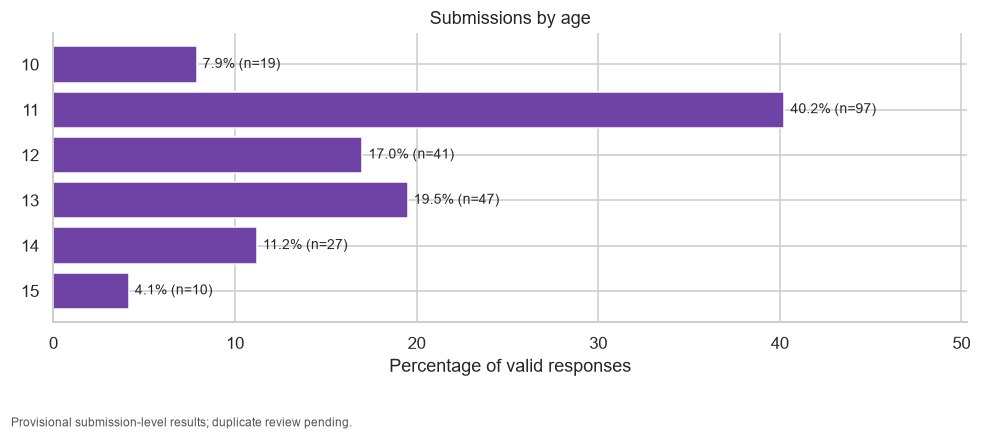

,category,count,percent,valid_n,missing_n
0,Female,138,57.261411,241,0
1,Male,102,42.323651,241,0
2,Prefer not to say,1,0.414938,241,0


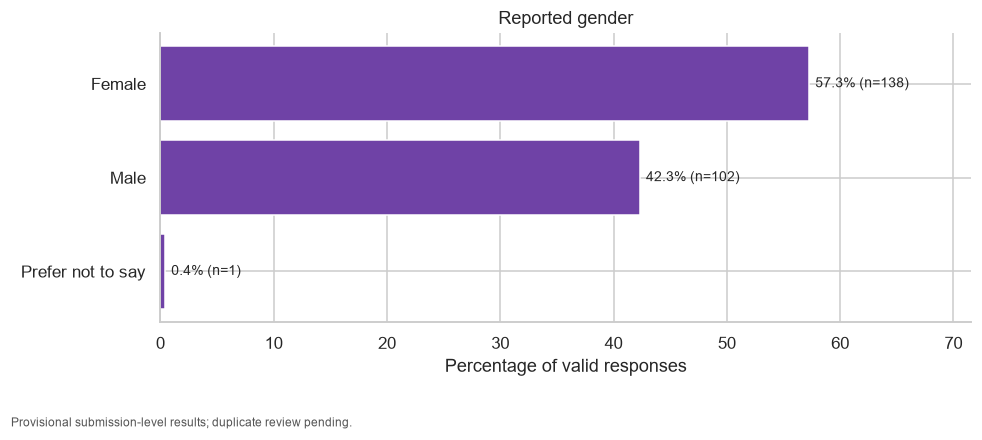

,category,count,percent,valid_n,missing_n
0,Yes,6,2.489627,241,0
1,No,235,97.510373,241,0


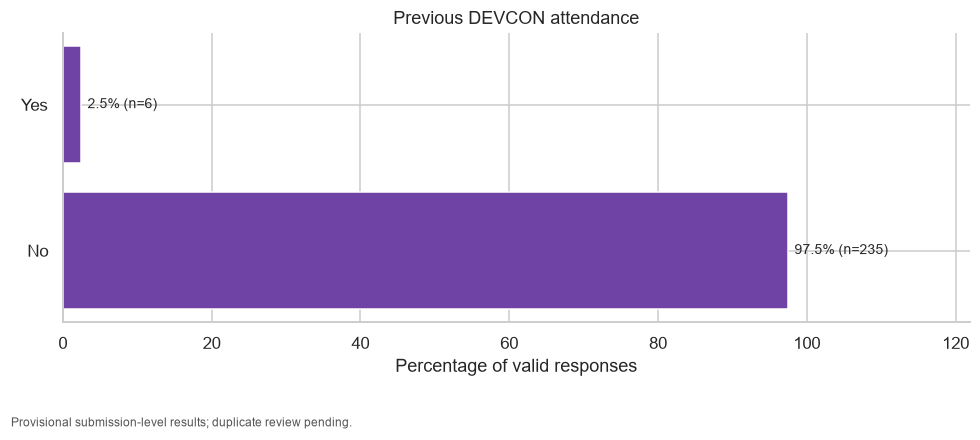

,category,count,percent,valid_n,missing_n
0,Yes,50,20.746888,241,0
1,No,191,79.253112,241,0


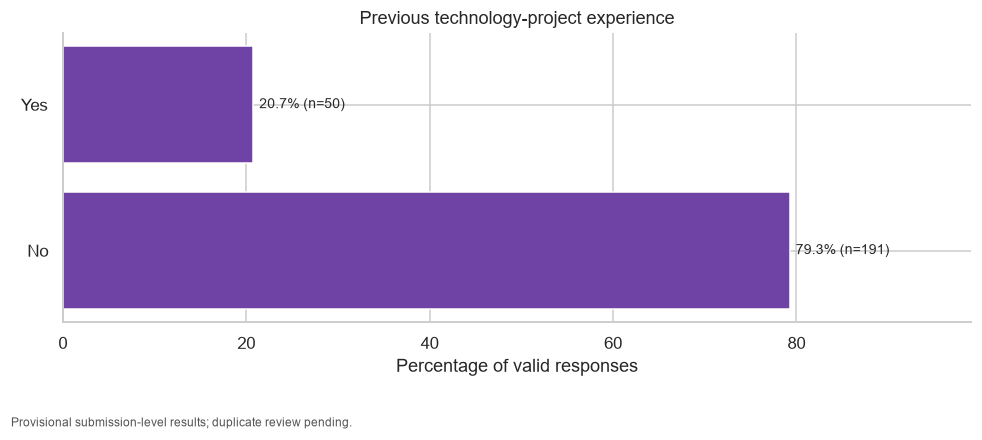

,category,count,percent,valid_n,missing_n
0,Not familiar,3,1.244813,241,0
1,Heard about it,21,8.713693,241,0
2,Somewhat familiar,103,42.738589,241,0
3,Very familiar,114,47.302905,241,0


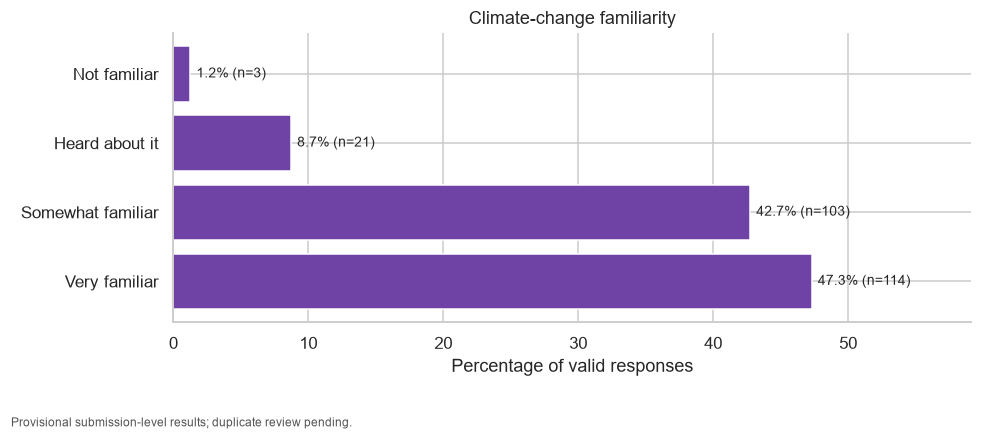

,category,count,percent,valid_n,missing_n
0,Yes,107,44.398340,241,0
1,No,77,31.950207,241,0
2,I'm not sure,57,23.651452,241,0


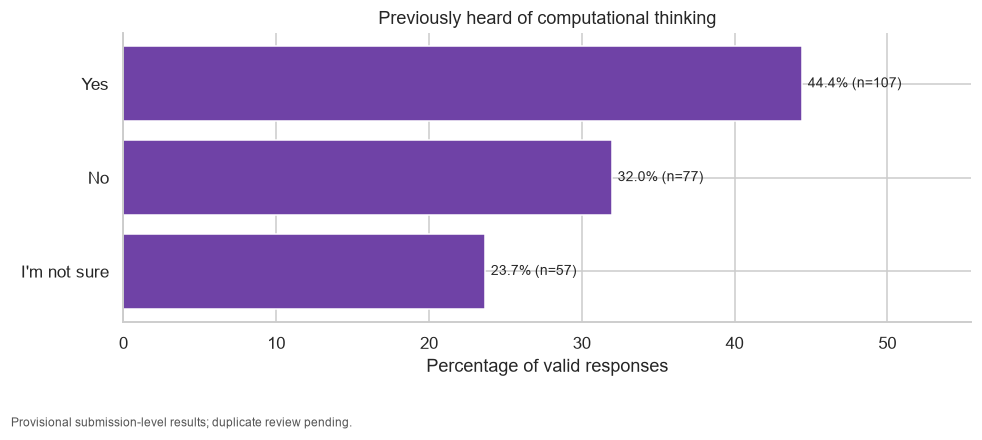

,category,count,percent,valid_n,missing_n
0,1,53,21.991701,241,0
1,2,61,25.311203,241,0
2,3,81,33.609959,241,0
3,4,33,13.692946,241,0
4,5,13,5.394191,241,0


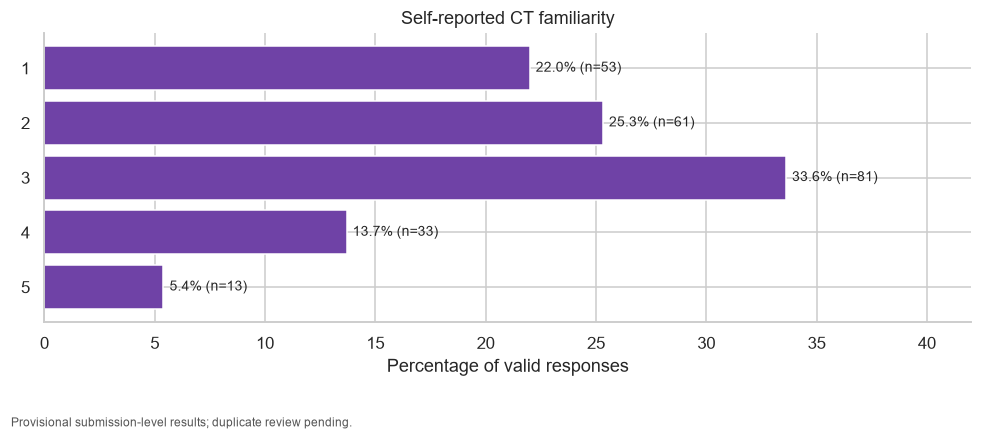

,category,count,percent,valid_n,missing_n
0,1,2,0.829876,241,0
1,2,16,6.639004,241,0
2,3,55,22.821577,241,0
3,4,70,29.045643,241,0
4,5,98,40.6639,241,0


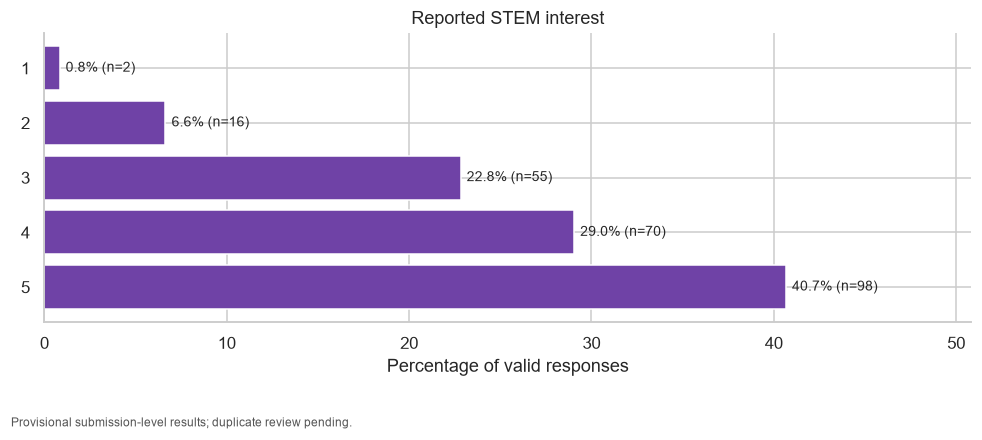

In [8]:
analysis_specs = [
    (
        "grade_level",
        ["Grade 5", "Grade 6", "Grade 7", "Grade 8", "Grade 9"],
        "Submissions by grade level",
    ),
    (
        "age",
        sorted(df["age"].dropna().unique()),
        "Submissions by age",
    ),
    (
        "gender",
        ["Female", "Male", "Prefer not to say"],
        "Reported gender",
    ),
    (
        "prior_devcon",
        ["Yes", "No"],
        "Previous DEVCON attendance",
    ),
    (
        "project_experience",
        ["Yes", "No"],
        "Previous technology-project experience",
    ),
    (
        "climate_familiarity",
        [
            "Not familiar",
            "Heard about it",
            "Somewhat familiar",
            "Very familiar",
        ],
        "Climate-change familiarity",
    ),
    (
        "heard_of_ct",
        ["Yes", "No", "I'm not sure"],
        "Previously heard of computational thinking",
    ),
    (
        "ct_familiarity_score",
        [1, 2, 3, 4, 5],
        "Self-reported CT familiarity",
    ),
    (
        "stem_interest",
        [1, 2, 3, 4, 5],
        "Reported STEM interest",
    ),
]

for column, order, title in analysis_specs:
    table = frequency_table(df[column], order)
    tables[column] = table

    display(table)

    bar_figure(
        table,
        title,
        f"students_{column}.png",
    )

tables["school_distribution"] = frequency_table(df["school_name"])

## 8. Summarize Checkbox Responses

Count each response once per selected option.

Technology frequencies use standardized labels and exclude
contradictory technology answers.

Environmental and climate-technology selections are split into options
for inspection. Free-text additions and unusual labels require review.

Multiple selections are allowed, so percentages may exceed 100%.

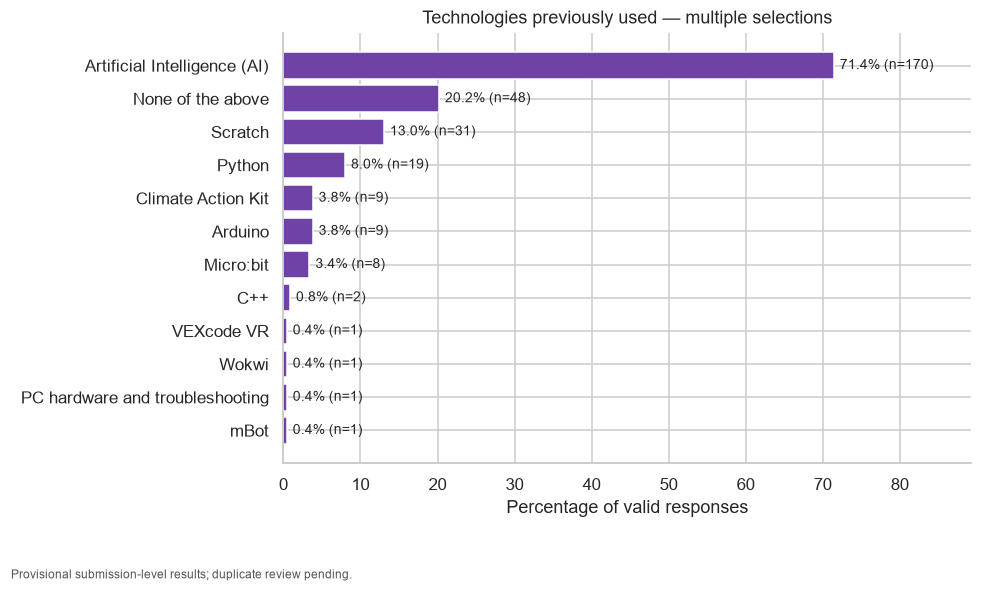

,category,count,percent,valid_n,excluded_or_missing_n
0,Extreme heat,178,73.858921,241,0
1,Typhoons,171,70.954357,241,0
2,Improper waste disposal,163,67.634855,241,0
3,Flooding,157,65.145228,241,0
4,Air pollution,102,42.323651,241,0
5,Plastic pollution,94,39.004149,241,0
6,Water shortage,64,26.556017,241,0
7,Earthquakes,1,0.414938,241,0
8,air pollution,1,0.414938,241,0
9,Scattered trash around our environment,1,0.414938,241,0


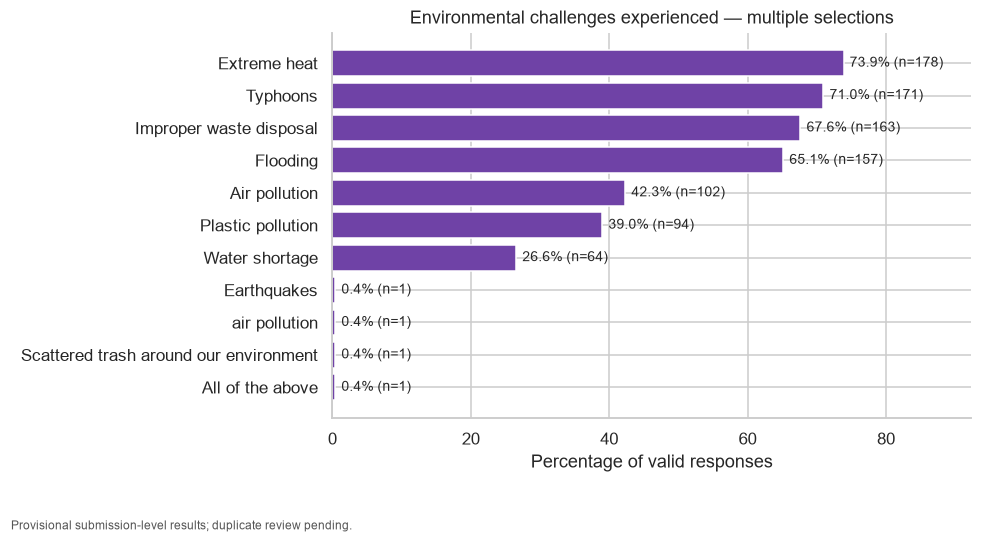

,category,count,percent,valid_n,excluded_or_missing_n
0,Monitor weather and floods,163,67.634855,241,0
1,Reduce waste through smart solutions,158,65.560166,241,0
2,Track environmental data,131,54.356846,241,0
3,Create early warning systems,108,44.813278,241,0
4,I don't know,1,0.414938,241,0


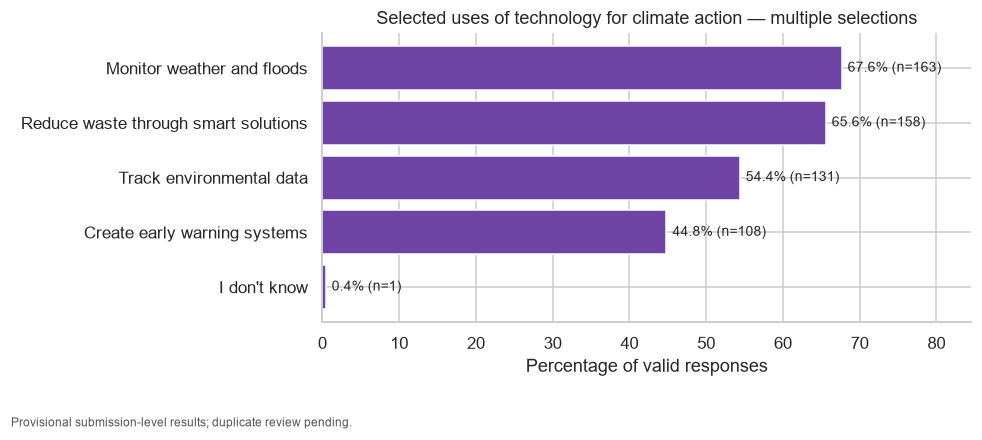

In [9]:
def multi_select_table(list_series, valid_mask):
    valid_lists = list_series.loc[valid_mask]
    denominator = len(valid_lists)

    tokens = [
        option
        for options in valid_lists
        for option in set(options)
    ]

    counts = pd.Series(tokens, dtype="string").value_counts()

    result = counts.rename_axis("category").reset_index(name="count")
    result["percent"] = (
        result["count"] / denominator * 100
        if denominator
        else np.nan
    )
    result["valid_n"] = denominator
    result["excluded_or_missing_n"] = len(list_series) - denominator

    return result


def split_checkbox(value):
    if pd.isna(value):
        return []

    return list(dict.fromkeys(
        item.strip()
        for item in str(value).split(",")
        if item.strip()
    ))


tables["technology_exposure"] = multi_select_table(
    tech_lists,
    technology_valid,
)

bar_figure(
    tables["technology_exposure"],
    "Technologies previously used — multiple selections",
    "students_technology_exposure.png",
)

for column, title in [
    ("environmental_challenges", "Environmental challenges experienced"),
    ("climate_tech_uses", "Selected uses of technology for climate action"),
]:
    selections = df[column].map(split_checkbox)
    valid = selections.map(len).gt(0)

    tables[column] = multi_select_table(selections, valid)

    display(tables[column])

    bar_figure(
        tables[column],
        title + " — multiple selections",
        f"students_{column}.png",
    )

## 9. Visualize Self-Reported Skills and Attitudes

Show the distribution of ratings 1–5 using 100% stacked bars.

These are self-reported ratings, not objective performance scores.
Numeric rating labels are used because verbal anchors must be checked
against the original questionnaire.

No overall score is created by combining unrelated questions.

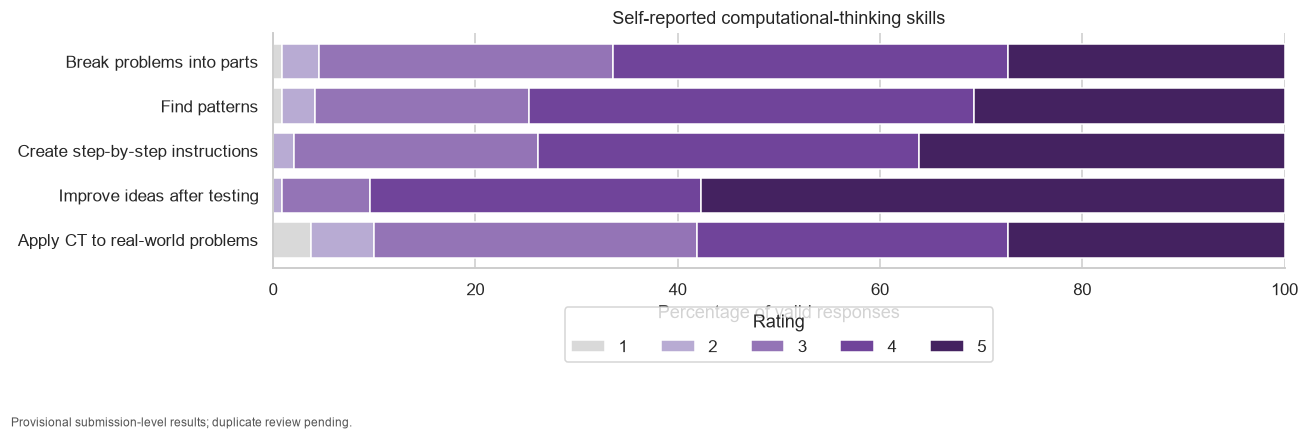

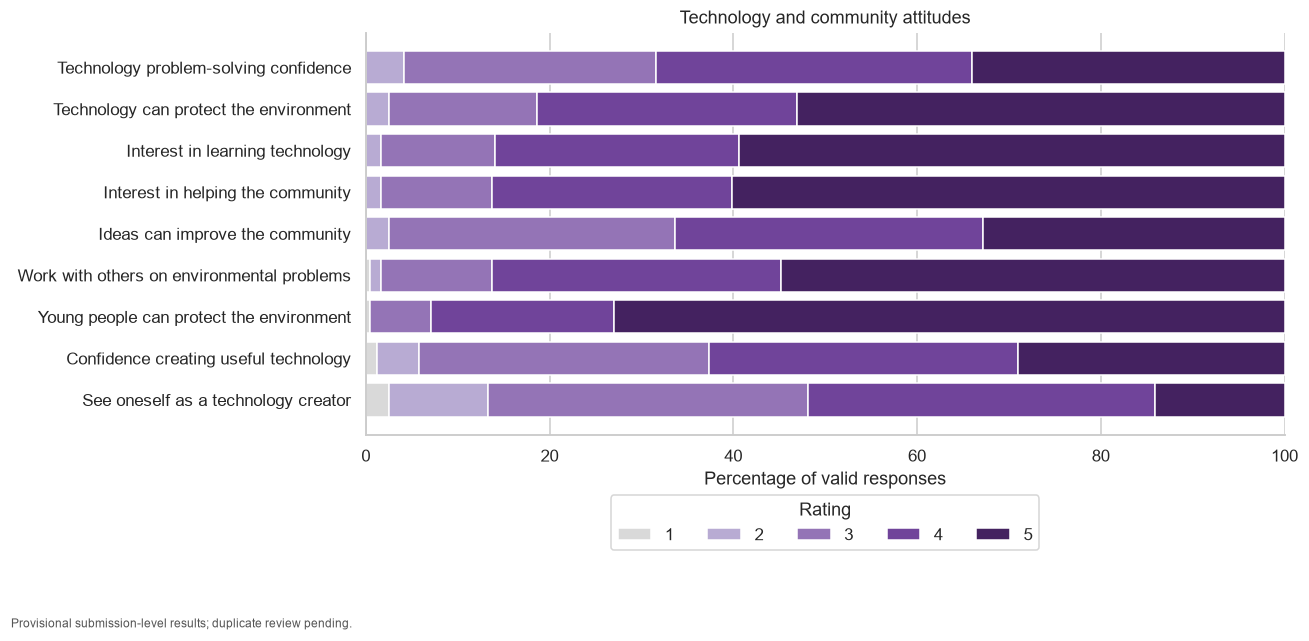

In [10]:
CT_SKILLS = {
    "ct_decomposition": "Break problems into parts",
    "ct_patterns": "Find patterns",
    "ct_steps": "Create step-by-step instructions",
    "ct_iteration": "Improve ideas after testing",
    "ct_application": "Apply CT to real-world problems",
}

ATTITUDES = {
    "tech_confidence": "Technology problem-solving confidence",
    "environment_belief": "Technology can protect the environment",
    "tech_interest": "Interest in learning technology",
    "community_tech_interest": "Interest in helping the community",
    "community_ideas": "Ideas can improve the community",
    "environmental_teamwork": "Work with others on environmental problems",
    "youth_impact": "Young people can protect the environment",
    "tech_creation_confidence": "Confidence creating useful technology",
    "tech_creator_identity": "See oneself as a technology creator",
}


def rating_figure(mapping, title, filename, table_name):
    rows = []

    for column, label in mapping.items():
        values = df[column].dropna()
        counts = values.value_counts().reindex(
            [1, 2, 3, 4, 5],
            fill_value=0,
        )

        row = {
            "item": label,
            "valid_n": len(values),
            "missing_n": int(df[column].isna().sum()),
            "median": values.median() if len(values) else np.nan,
        }

        for rating in range(1, 6):
            row[f"rating_{rating}_count"] = int(counts[rating])
            row[f"rating_{rating}_percent"] = (
                counts[rating] / len(values) * 100
                if len(values)
                else np.nan
            )

        rows.append(row)

    table = pd.DataFrame(rows)
    tables[table_name] = table

    fig, ax = plt.subplots(
        figsize=(12, max(4, len(table) * 0.65))
    )

    left = np.zeros(len(table))

    for rating, color in zip(range(1, 6), RATING_COLORS):
        values = table[f"rating_{rating}_percent"].fillna(0).to_numpy()

        ax.barh(
            table["item"],
            values,
            left=left,
            color=color,
            label=str(rating),
        )

        left += values

    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentage of valid responses")
    ax.set_ylabel("")
    ax.set_title(title)
    ax.legend(title="Rating", ncol=5, loc="upper center",
              bbox_to_anchor=(0.5, -0.13))

    save_figure(fig, filename)


rating_figure(
    CT_SKILLS,
    "Self-reported computational-thinking skills",
    "students_ct_skills.png",
    "ct_skill_ratings",
)

rating_figure(
    ATTITUDES,
    "Technology and community attitudes",
    "students_attitudes.png",
    "attitude_ratings",
)

## 10. Explore Relationships and Grade Differences

Use Spearman correlations to explore associations among selected
ordered ratings.

Compare STEM-interest distributions within grades. These relationships
are descriptive and do not demonstrate causation.

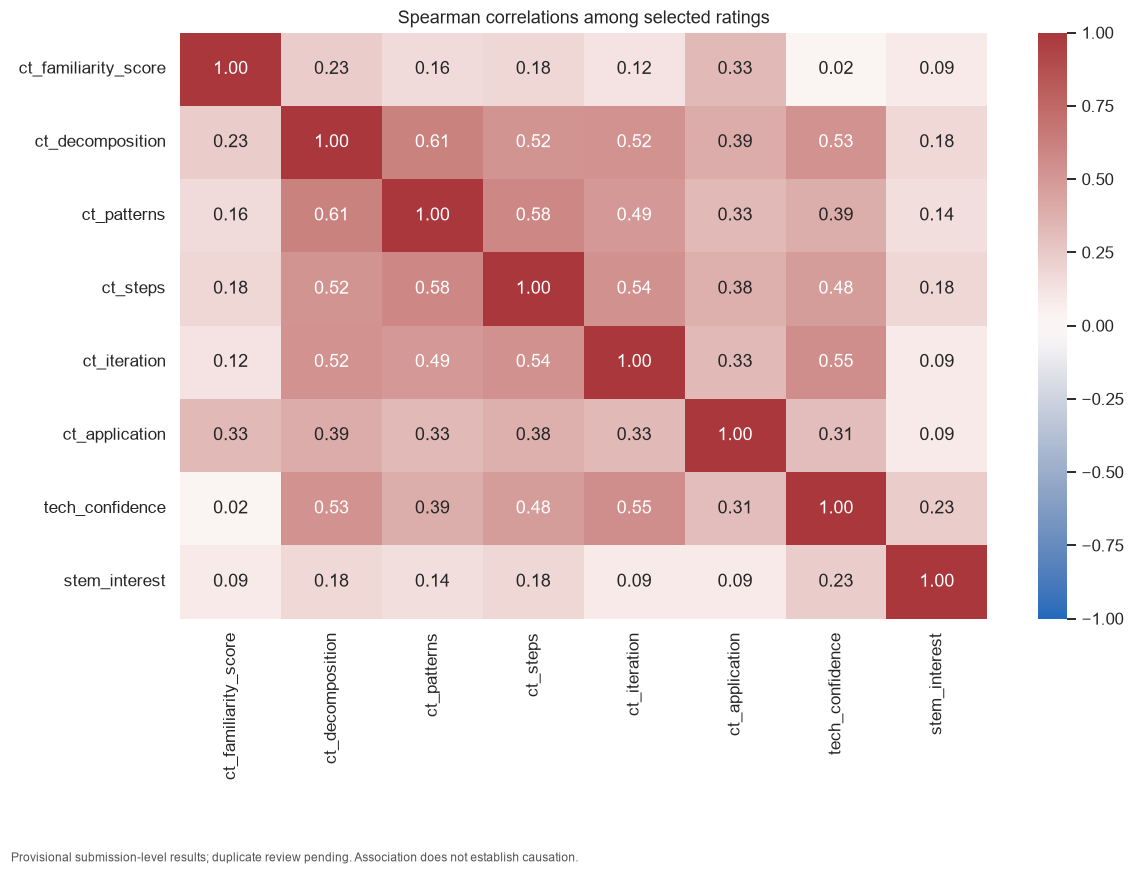

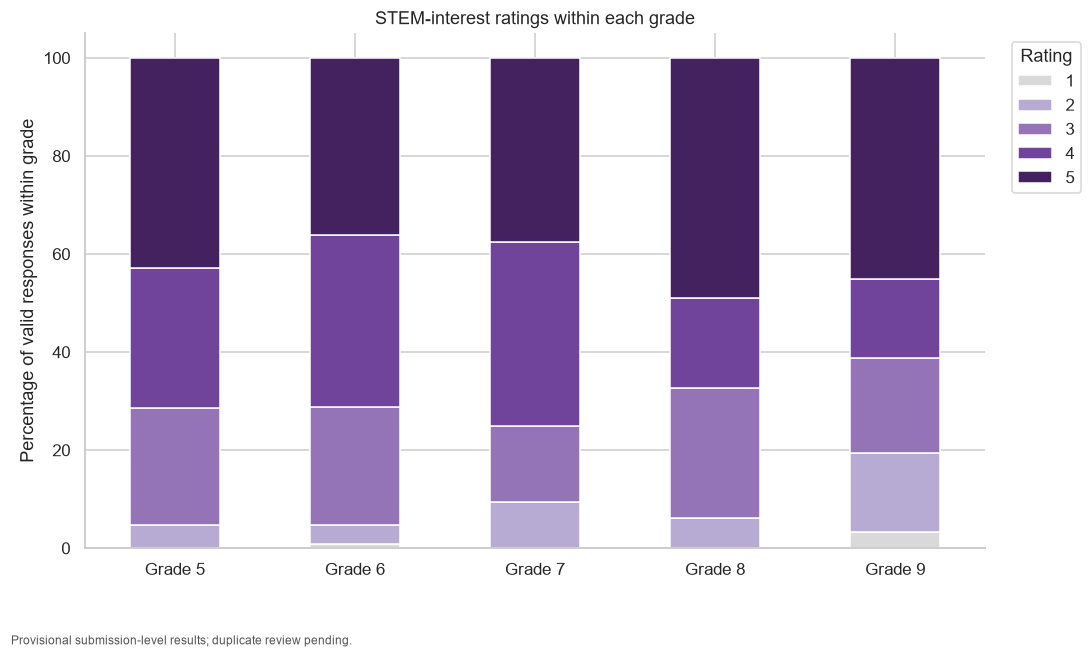

In [11]:
correlation_columns = [
    "ct_familiarity_score",
    "ct_decomposition",
    "ct_patterns",
    "ct_steps",
    "ct_iteration",
    "ct_application",
    "tech_confidence",
    "stem_interest",
]

numeric = df[correlation_columns].astype("float64")

correlations = numeric.corr(method="spearman")
pair_counts = numeric.notna().astype(int).T.dot(
    numeric.notna().astype(int)
)

tables["spearman_correlations"] = correlations
tables["correlation_pair_counts"] = pair_counts

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    ax=ax,
)

ax.set_title("Spearman correlations among selected ratings")

save_figure(
    fig,
    "students_spearman_correlations.png",
    "Association does not establish causation.",
)

grade_counts = pd.crosstab(
    df["grade_level"],
    df["stem_interest"],
).reindex(
    index=["Grade 5", "Grade 6", "Grade 7", "Grade 8", "Grade 9"],
    columns=[1, 2, 3, 4, 5],
    fill_value=0,
)

grade_percent = grade_counts.div(
    grade_counts.sum(axis=1).replace(0, np.nan),
    axis=0,
) * 100

tables["stem_by_grade_counts"] = grade_counts
tables["stem_by_grade_percent"] = grade_percent

ax = grade_percent.plot(
    kind="bar",
    stacked=True,
    color=RATING_COLORS,
    figsize=(10, 6),
    rot=0,
)

ax.set_title("STEM-interest ratings within each grade")
ax.set_xlabel("")
ax.set_ylabel("Percentage of valid responses within grade")
ax.legend(title="Rating", bbox_to_anchor=(1.02, 1))

save_figure(
    ax.get_figure(),
    "students_stem_interest_by_grade.png",
)

## 11. Summarize Reviewed Written-Response Themes

Read the manual coding file and summarize only responses marked as
reviewed.

The denominator is the number of reviewed responses for that question.
Responses may have multiple themes.

These results do not represent unreviewed answers.

In [12]:
coding = pd.read_csv(
    coding_path,
    keep_default_na=False,
    dtype={"response_id": "string"},
)

coding["reviewed_bool"] = (
    coding["reviewed"]
    .astype("string")
    .str.strip()
    .str.casefold()
    .isin(["true", "1", "yes"])
)

# Ignore records no longer present after verified exclusions.
coding = coding.loc[
    coding["response_id"].isin(df["response_id"])
].copy()

if coding.duplicated(["response_id", "question"]).any():
    raise ValueError(
        "The coding file contains duplicate response/question rows."
    )

for question in text_columns:
    reviewed = coding.loc[
        coding["question"].eq(question)
        & coding["reviewed_bool"]
    ].copy()

    if reviewed.empty:
        print(f"{question}: no reviewed themes yet.")
        continue

    theme_lists = reviewed["themes"].map(
        lambda value: list(dict.fromkeys(
            item.strip()
            for item in str(value).split(";")
            if item.strip()
        ))
    )

    theme_table = multi_select_table(
        theme_lists,
        pd.Series(True, index=theme_lists.index),
    )

    tables[f"themes_{question}"] = theme_table

    if not theme_table.empty:
        bar_figure(
            theme_table,
            f"Reviewed themes: {question}",
            f"students_themes_{question}.png",
            color=ORANGE,
        )

climate_problem: no reviewed themes yet.
learning_goals: no reviewed themes yet.
ct_definition: no reviewed themes yet.


## 12. Save the Standardized Dataset and Analysis Tables

Save the standardized dataset separately from the first cleaned file.

Export descriptive tables and review information. Review tables contain
identifying information and should not be included in public reports.

Unresolved duplicate candidates are retained here but will be excluded
from the preliminary prediction experiment.

In [13]:
quality_summary = pd.DataFrame({
    "metric": [
        "Submissions retained",
        "Confirmed submissions excluded",
        "Unresolved duplicate-candidate rows",
        "Technology-conflict rows",
        "Rows in schools with inconsistent clusters",
        "Invalid rating values",
    ],
    "count": [
        len(df),
        len(tables["excluded_submissions"]),
        int(df["possible_duplicate"].sum()),
        int(df["technology_conflict"].sum()),
        int(df["school_cluster_inconsistent"].sum()),
        len(tables["rating_validation"]),
    ],
})

tables["quality_summary"] = quality_summary
display(quality_summary)

standardized_path = CLEANED / "students_pre_event_standardized.xlsx"

# Matching keys are internal helpers, not analysis variables.
export_df = df.drop(columns=["name_key"], errors="ignore")

export_df.to_excel(
    standardized_path,
    sheet_name="Standardized Data",
    index=False,
)

with pd.ExcelWriter(
    TABLES / "students_analysis_tables.xlsx",
    engine="openpyxl",
) as writer:
    for sheet_name, table in tables.items():
        # Keep index labels for cross-tabulations and correlation matrices.
        include_index = not isinstance(table.index, pd.RangeIndex)

        table.to_excel(
            writer,
            sheet_name=sheet_name[:31],
            index=include_index,
        )

print("Saved:", standardized_path)
print("Figures:", FIGURES)
print("Tables:", TABLES)

,metric,count
0,Submissions retained,241
1,Confirmed submissions excluded,0
2,Unresolved duplicate-candidate rows,20
3,Technology-conflict rows,3
4,Rows in schools with inconsistent clusters,124
5,Invalid rating values,0


Saved: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\data\cleaned\students_pre_event_standardized.xlsx
Figures: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\figures\students
Tables: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\SEPTEMBER _6_DATA\outputs\tables\students
